saved bicycle_sales_focus.png


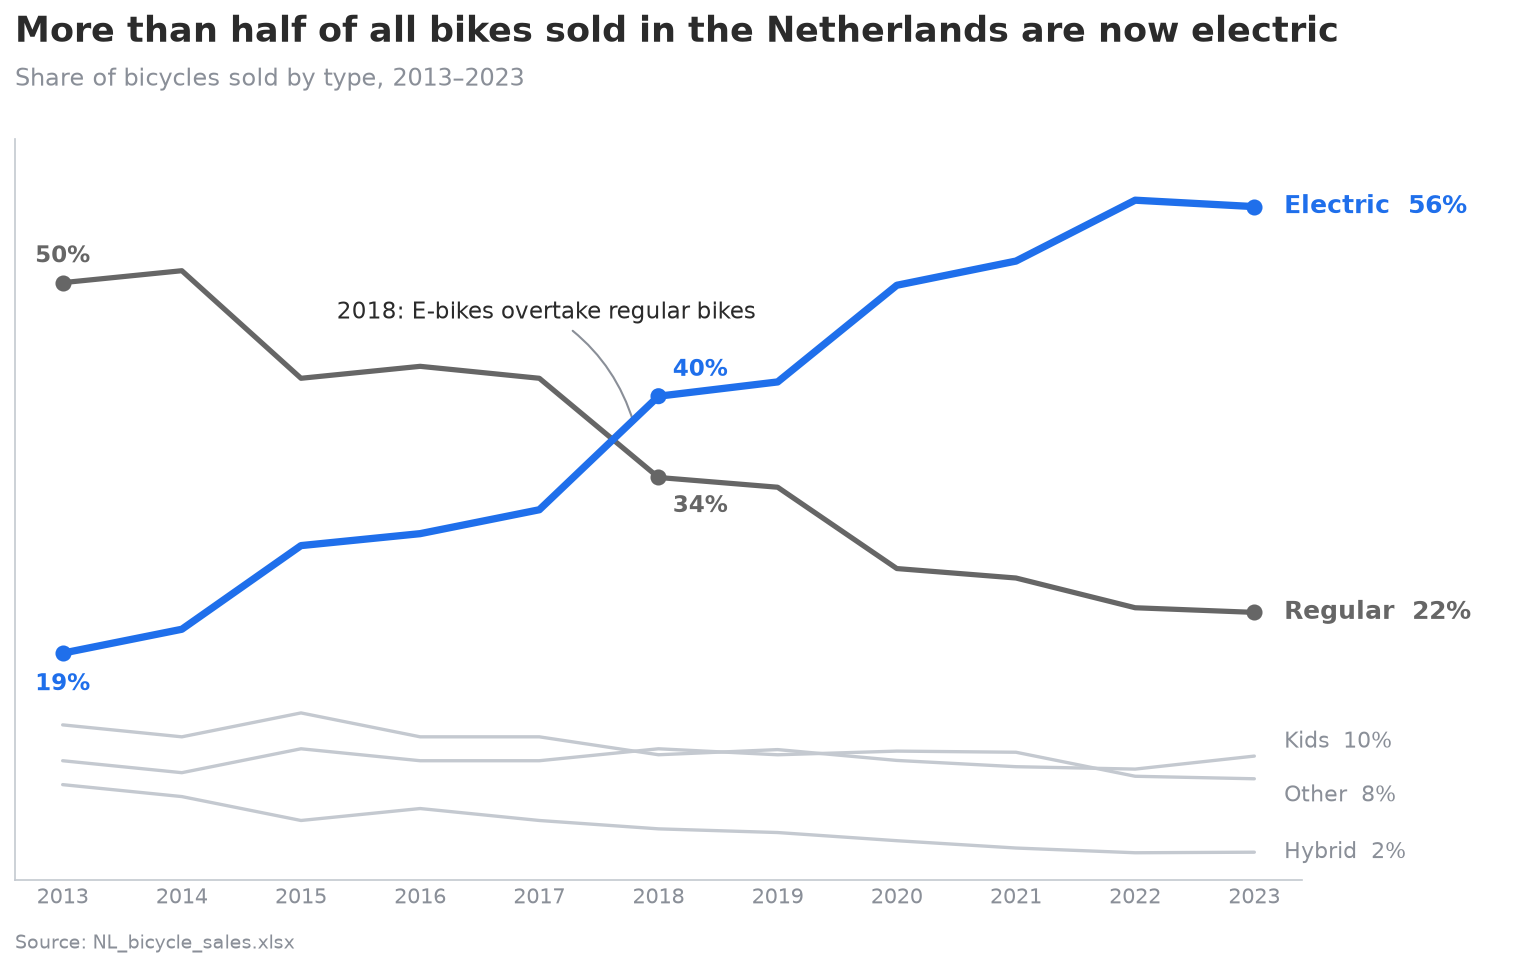

In [18]:
"""Dutch bicycle sales by type (share of units sold), 2013-2023.

Focusing attention: everything is grey except the story -
electric bicycles overtaking regular bicycles. The title states the
takeaway, and lines are labelled directly (no legend to look up).
"""
from openpyxl import load_workbook
import matplotlib.pyplot as plt

# Put NL_bicycle_sales.xlsx in the same folder as this script / notebook.
# Read with openpyxl directly (no pandas needed).
rows = list(load_workbook("NL_bicycle_sales.xlsx", data_only=True).active.values)
header = [str(h).strip() for h in rows[0]]
data = [r for r in rows[1:] if r[0] is not None]
years = [int(r[0]) for r in data]
df = {col: [r[i] * 100 for r in data]  # share -> percent
      for i, col in enumerate(header) if i > 0 and rows[0][i] is not None}

FOCUS = "#1F6FEB"      # the one colour that grabs attention
SECOND = "#666666"     # the contrast line, darker grey
CONTEXT = "#C4C9D0"    # everything else recedes
INK = "#2B2B2B"
MUTED = "#8A8F98"

style = {
    "Electric bicycles": dict(color=FOCUS, lw=3.5, z=4),
    "Regular bicycles": dict(color=SECOND, lw=2.5, z=3),
}

fig, ax = plt.subplots(figsize=(11, 6.5), dpi=150)

for col in df:
    s = style.get(col, dict(color=CONTEXT, lw=1.6, z=2))
    ax.plot(years, df[col], color=s["color"], lw=s["lw"], zorder=s["z"],
            solid_capstyle="round")
    # Direct label at the line's end
    end = df[col][-1]
    name = col.replace(" bicycles", "")
    offset = {"Kids": 1.2, "Other": -1.4, "Hybrid": 0}.get(name, 0)
    bold = col in style
    ax.text(years[-1] + 0.25, end + offset, f"{name}  {end:.0f}%",
            va="center", fontsize=12 if bold else 10.5,
            fontweight="bold" if bold else "normal",
            color=s["color"] if bold else MUTED)

# Start and end points for the two focus lines (values are on the y-axis)
for col in style:
    ax.scatter([years[0], years[-1]], [df[col][0], df[col][-1]], s=45,
               color=style[col]["color"], zorder=5)

# Value labels: 2013 start and 2018 crossover (above for e-bikes' rise, below for regular)
i18 = years.index(2018)
ax.scatter([2018, 2018], [df["Electric bicycles"][i18], df["Regular bicycles"][i18]],
           s=45, color=[FOCUS, SECOND], zorder=5)
for col, i, dx, dy, ha in [
    ("Regular bicycles", 0, 0, 2.2, "center"),
    ("Electric bicycles", 0, 0, -2.6, "center"),
    ("Electric bicycles", i18, 0.12, 2.2, "left"),
    ("Regular bicycles", i18, 0.12, -2.4, "left"),
]:
    v = df[col][i]
    ax.text(years[i] + dx, v + dy, f"{v:.0f}%", ha=ha, va="center",
            fontsize=11, fontweight="bold", color=style[col]["color"])

# Annotate the crossover between 2017 and 2018
ax.annotate("2018: E-bikes overtake regular bikes",
            xy=(2017.8, 38), xytext=(2015.3, 47),
            fontsize=11, color=INK,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=1,
                            connectionstyle="arc3,rad=-0.2"))

# Axes: x and y axis lines visible, y starts at 0. No box, no grid.
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("bottom", "left"):
    ax.spines[side].set_color(CONTEXT)
ax.tick_params(axis="both", colors=MUTED, labelsize=10, length=0)
ax.set_xticks(years)
ax.set_yticks([])  # key values are labelled directly, so no y tick labels
ax.set_xlim(years[0] - 0.4, years[-1] + 2.2)
ax.set_ylim(0, 62)
ax.spines["bottom"].set_bounds(years[0] - 0.4, years[-1] + 0.4)

fig.text(0.06, 0.95, "More than half of all bikes sold in the Netherlands are now electric",
         fontsize=17, fontweight="bold", color=INK)
fig.text(0.06, 0.905,
         "Share of bicycles sold by type, 2013–2023",
         fontsize=11.5, color=MUTED)
fig.text(0.06, 0.02, "Source: NL_bicycle_sales.xlsx", fontsize=9, color=MUTED)

fig.subplots_adjust(left=0.06, right=0.97, top=0.85, bottom=0.09)
fig.savefig("bicycle_sales_focus.png", facecolor="white")
print("saved bicycle_sales_focus.png")
